In [18]:
# 딥러닝을 이용한 이미지 분류
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [19]:
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

In [20]:
print(train_images.shape, train_labels.shape)
print(test_images.shape, train_labels.shape)

(50000, 32, 32, 3) (50000, 1)
(10000, 32, 32, 3) (50000, 1)


In [21]:
train_images[0]

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

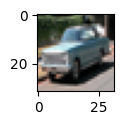

In [22]:
plt.figure(figsize = (1, 1))
plt.imshow(train_images[32]) # 아무번호나 찍어본거임. 32 아무 의미 없음

In [23]:
train_images = train_images / 255.0	# 이미지 정규화
test_images = test_images / 255.0	# 이미지 정규화

In [24]:
train_images[0]

array([[[0.23137255, 0.24313725, 0.24705882],
        [0.16862745, 0.18039216, 0.17647059],
        [0.19607843, 0.18823529, 0.16862745],
        ...,
        [0.61960784, 0.51764706, 0.42352941],
        [0.59607843, 0.49019608, 0.4       ],
        [0.58039216, 0.48627451, 0.40392157]],

       [[0.0627451 , 0.07843137, 0.07843137],
        [0.        , 0.        , 0.        ],
        [0.07058824, 0.03137255, 0.        ],
        ...,
        [0.48235294, 0.34509804, 0.21568627],
        [0.46666667, 0.3254902 , 0.19607843],
        [0.47843137, 0.34117647, 0.22352941]],

       [[0.09803922, 0.09411765, 0.08235294],
        [0.0627451 , 0.02745098, 0.        ],
        [0.19215686, 0.10588235, 0.03137255],
        ...,
        [0.4627451 , 0.32941176, 0.19607843],
        [0.47058824, 0.32941176, 0.19607843],
        [0.42745098, 0.28627451, 0.16470588]],

       ...,

       [[0.81568627, 0.66666667, 0.37647059],
        [0.78823529, 0.6       , 0.13333333],
        [0.77647059, 0

In [25]:
val_images = train_images[45000:]
val_labels = train_labels[45000:]

train_images = train_images[:45000]
train_labels = train_labels[:45000]

In [26]:
mlp_model = Sequential([
    Flatten(input_shape = (32, 32, 3)),
    Dense(512, activation = 'relu'),
    Dense(256, activation = 'relu'),
    Dense(128, activation = 'relu'),
    Dense(10, activation = 'softmax')
])

In [27]:
mlp_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 3072)              0         
                                                                 
 dense_2 (Dense)             (None, 512)               1573376   
                                                                 
 dense_3 (Dense)             (None, 256)               131328    
                                                                 
 dense_4 (Dense)             (None, 128)               32896     
                                                                 
 dense_5 (Dense)             (None, 10)                1290      
                                                                 
Total params: 1738890 (6.63 MB)
Trainable params: 1738890 (6.63 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [28]:
mlp_model.compile(optimizer = 'adam',
                  loss = 'sparse_categorical_crossentropy',
                  metrics = ['accuracy'])

In [29]:
mlp_model.fit(train_images,
              train_labels,
              epochs = 5,
              validation_data = (val_images, val_labels))

Epoch 1/5


1407/1407 [==============================] - 7s 5ms/step - loss: 1.8811 - accuracy: 0.3184 - val_loss: 1.7483 - val_accuracy: 0.3722
Epoch 2/5
1407/1407 [==============================] - 6s 5ms/step - loss: 1.6863 - accuracy: 0.3932 - val_loss: 1.7249 - val_accuracy: 0.3870
Epoch 3/5
1407/1407 [==============================] - 6s 5ms/step - loss: 1.6076 - accuracy: 0.4253 - val_loss: 1.5972 - val_accuracy: 0.4362
Epoch 4/5
1407/1407 [==============================] - 6s 5ms/step - loss: 1.5507 - accuracy: 0.4412 - val_loss: 1.6131 - val_accuracy: 0.4320
Epoch 5/5
1407/1407 [==============================] - 6s 4ms/step - loss: 1.5135 - accuracy: 0.4564 - val_loss: 1.5411 - val_accuracy: 0.4524


In [30]:
mlp_model.evaluate(test_images, test_labels)

313/313 [==============================] - 0s 2ms/step - loss: 1.5332 - accuracy: 0.4528


[1.533159852027893, 0.4528000056743622]

In [31]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Dense, Flatten
from tensorflow.keras.models import Sequential


In [32]:
cnn_model = Sequential([Conv2D(32,
                               (3, 3),
                               padding = 'same',
                               activation = 'relu',
                               input_shape = (32, 32, 3)),
                        MaxPooling2D((2,2)),
                        Conv2D(32,
                               (3, 3),
				   padding = 'same', 
                   		   activation = 'relu'),
                        MaxPooling2D((2,2)),
                        Conv2D(64,
                               (3, 3),
                   		   padding = 'same',
                   		   activation = 'relu'),
                        Flatten(),
                        Dropout(0.3),
                        Dense(64, activation = 'relu'),
                        Dropout(0.5),
                        Dense(10, activation = 'softmax')])

In [33]:
cnn_model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 32, 32, 32)        896       
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 16, 16, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (None, 16, 16, 32)        9248      
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 8, 8, 32)          0         
 g2D)                                                            
                                                                 
 conv2d_8 (Conv2D)           (None, 8, 8, 64)          18496     
                                                                 
 flatten_2 (Flatten)         (None, 4096)             

In [34]:
cnn_model.compile(optimizer = 'adam',
                  loss = 'sparse_categorical_crossentropy',
                  metrics = ['accuracy'])

In [35]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(monitor = 'val_loss',			# loss가 줄어들다 다시 올라가는 시점에 그냥 스탑 시킴
                               patience = 5)
save_best_only = ModelCheckpoint('best_cifar10_cnn_model.h5',	# 스탑시켰을 때의 모델을 베스트 모델로 선정한 후 저장
                                 save_best_only = True)

In [69]:
history = cnn_model.fit(train_images,
                        train_labels,
                        batch_size = 512,
                        epochs = 100,
                        validation_data = (val_images, val_labels),
                        callbacks = [early_stopping, save_best_only])

Epoch 1/100
88/88 [==============================] - 4s 49ms/step - loss: 0.4906 - accuracy: 0.8202 - val_loss: 0.7308 - val_accuracy: 0.7680
Epoch 2/100
88/88 [==============================] - 4s 48ms/step - loss: 0.4762 - accuracy: 0.8203 - val_loss: 0.7472 - val_accuracy: 0.7630
Epoch 3/100
88/88 [==============================] - 5s 54ms/step - loss: 0.4870 - accuracy: 0.8183 - val_loss: 0.7306 - val_accuracy: 0.7706
Epoch 4/100
88/88 [==============================] - 5s 52ms/step - loss: 0.4844 - accuracy: 0.8199 - val_loss: 0.7228 - val_accuracy: 0.7670
Epoch 5/100
88/88 [==============================] - 5s 53ms/step - loss: 0.4822 - accuracy: 0.8188 - val_loss: 0.7321 - val_accuracy: 0.7666
Epoch 6/100
88/88 [==============================] - 5s 54ms/step - loss: 0.4760 - accuracy: 0.8244 - val_loss: 0.7476 - val_accuracy: 0.7636
Epoch 7/100
88/88 [==============================] - 5s 53ms/step - loss: 0.4786 - accuracy: 0.8208 - val_loss: 0.7363 - val_accuracy: 0.7668
Epoch 

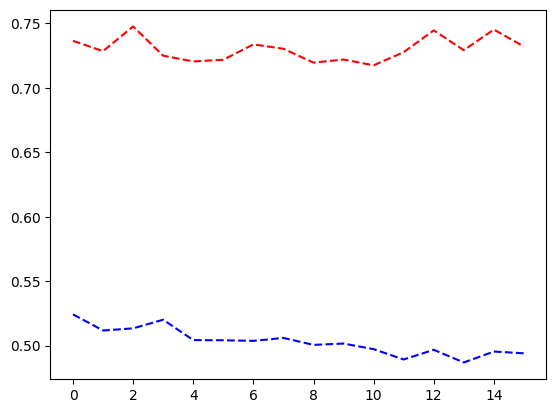

In [63]:
plt.plot(history.history['loss'], 'b--')
plt.plot(history.history['val_loss'], 'r--')
plt.show()

In [64]:
cnn_model.evaluate(test_images, test_labels)

313/313 [==============================] - 1s 3ms/step - loss: 0.7671 - accuracy: 0.7652


[0.7670626044273376, 0.7652000188827515]

In [65]:
predicted_labels = cnn_model.predict(test_images)
predicted_labels.shape

313/313 [==============================] - 1s 2ms/step


(10000, 10)

In [66]:
import tensorflow as tf

predicted_labels = tf.argmax(predicted_labels, axis = 1)
predicted_labels

<tf.Tensor: shape=(10000,), dtype=int64, numpy=array([3, 8, 8, ..., 5, 1, 7], dtype=int64)>

In [67]:
label_to_name = {
    0 : 'airplane',
    1 : 'automobile',
    2 : 'bird',
    3 : 'cat',
    4 : 'deer',
    5 : 'dog',
    6 : 'frog',
    7 : 'horse',
    8 : 'ship',
    9 : 'truck'
}

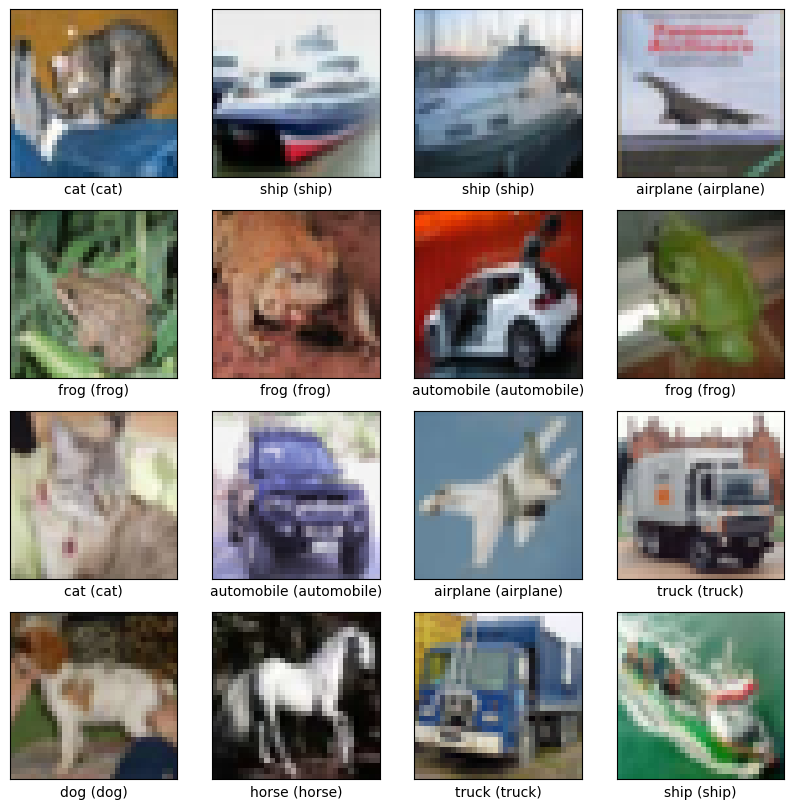

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 10))
for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(test_images[i], cmap = plt.cm.binary)
    xlabel = f"{label_to_name[int(test_labels[i][0])]} ({label_to_name[int(predicted_labels[i])]})"
    plt.xlabel(xlabel, color='red' if test_labels[i][0] != predicted_labels[i] else 'black')